# Model IV
## Rozpoznawanie instrumentów za pomocą konwolucji (ResNet50)

### Biblioteki

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

from model import Resnet
from trening import get_device, train_model
from przygotowanie_danych import (
    INSTRUMENTS,
    create_datasets,
    create_loaders
)

In [3]:
epochs = 100
patience = 10
batch_size = 32
learning_rate = 0.0001

dropout = 0.3

threshold = 0.8

expression = f"Resnet_batch{batch_size}_lr{learning_rate}_dr{dropout}"
weights_filename = f"weights_{expression}.pth"

In [4]:
train_dataset, val_dataset, test_dataset = create_datasets()

train_loader, val_loader, test_loader = create_loaders(train_dataset, val_dataset, test_dataset, batch_size=batch_size)

In [5]:
device = get_device()
print(device)

model = Resnet(dropout=dropout).to(device)

criterion = nn.MultiLabelSoftMarginLoss()

optimizer = optim.Adam(model.parameters(), lr=learning_rate)

cuda


In [13]:
X, y = next(iter(train_loader))

print("Wejście do ResNet:", X.shape)
print("Etykiety:", y.shape)
print("Warstwa wejściowa:", model.model.conv1)
print("Wyjście modelu:", model(X.to(device)).shape)

Wejście do ResNet: torch.Size([32, 1, 128, 346])
Etykiety: torch.Size([32, 7])
Warstwa wejściowa: Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
Wyjście modelu: torch.Size([32, 7])


In [6]:
start_time = time.perf_counter()

model, history, best_epoch, best_val_loss = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=epochs,
    patience=patience,
    model_name= str(weights_filename)
)

training_time = time.perf_counter() - start_time

print(f"Czas treningu: {training_time / 60:.2f} min")

Epoka 1/100 | Train loss: 0.4412 | Val loss: 0.3005
Epoka 2/100 | Train loss: 0.2466 | Val loss: 0.2103
Epoka 3/100 | Train loss: 0.1685 | Val loss: 0.2020
Epoka 4/100 | Train loss: 0.1143 | Val loss: 0.1841
Epoka 5/100 | Train loss: 0.0787 | Val loss: 0.1667
Epoka 6/100 | Train loss: 0.0549 | Val loss: 0.1596
Epoka 7/100 | Train loss: 0.0481 | Val loss: 0.1792
Epoka 8/100 | Train loss: 0.0395 | Val loss: 0.1909
Epoka 9/100 | Train loss: 0.0364 | Val loss: 0.1683
Epoka 10/100 | Train loss: 0.0308 | Val loss: 0.1828
Epoka 11/100 | Train loss: 0.0250 | Val loss: 0.2074
Epoka 12/100 | Train loss: 0.0231 | Val loss: 0.1767
Epoka 13/100 | Train loss: 0.0203 | Val loss: 0.1791
Epoka 14/100 | Train loss: 0.0206 | Val loss: 0.2046
Epoka 15/100 | Train loss: 0.0184 | Val loss: 0.1773
Epoka 16/100 | Train loss: 0.0197 | Val loss: 0.2133
Brak poprawy przez 10 epok.
Najlepsza epoka: 6
Najlepszy validation loss: 0.1596
Czas treningu: 31.08 min


In [7]:
instrument_names = list(INSTRUMENTS.values())

model.eval()

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        logits = model(X)
        probabilities = torch.sigmoid(logits).cpu().numpy()
        predictions = (probabilities >= threshold).astype(int)
        true_labels = y.cpu().numpy().astype(int)

        print("Prawdopodobieństwa:")
        display(pd.DataFrame(probabilities, columns=instrument_names).round(3))
        
        print("Przewidywane etykiety:")
        display(pd.DataFrame(predictions, columns=instrument_names))
        
        print("Prawdziwe etykiety:")
        display(pd.DataFrame(true_labels, columns=instrument_names))

        break

Prawdopodobieństwa:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,0.996,0.850,0.001,0.015,1.000,0.026,1.000
1,0.664,0.070,1.000,1.000,0.997,0.135,0.001
2,1.000,0.003,0.849,0.000,0.001,0.058,1.000
3,1.000,0.997,1.000,0.003,0.991,0.002,1.000
4,0.000,1.000,1.000,0.000,1.000,0.001,0.007
5,0.050,0.073,0.606,0.996,0.009,0.966,0.997
6,0.001,0.003,0.001,0.021,0.000,0.806,1.000
7,1.000,0.064,0.961,0.002,0.104,0.157,0.995
8,0.993,0.036,0.990,1.000,0.995,0.003,0.002
9,0.995,0.927,0.001,1.000,0.861,0.002,0.089


Przewidywane etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,1,0,0,1,0,1
1,0,0,1,1,1,0,0
2,1,0,1,0,0,0,1
3,1,1,1,0,1,0,1
4,0,1,1,0,1,0,0
5,0,0,0,1,0,1,1
6,0,0,0,0,0,1,1
7,1,0,1,0,0,0,1
8,1,0,1,1,1,0,0
9,1,1,0,1,1,0,0


Prawdziwe etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,1,0,0,1,0,1
1,1,0,1,1,1,1,0
2,1,0,1,0,0,1,1
3,1,1,1,0,1,0,1
4,0,1,1,0,1,0,0
5,0,0,1,1,0,1,1
6,0,0,0,0,0,0,1
7,1,0,1,0,0,1,1
8,1,0,0,1,0,0,1
9,1,1,0,1,1,0,1


In [8]:
model.eval()

all_predictions = []
all_labels = []

val_loss = 0.0

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)

        loss = criterion(logits, y)
        val_loss += loss.item() * X.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= threshold).float()

        all_predictions.append(predictions.cpu().numpy())
        all_labels.append(y.cpu().numpy())

val_loss /= len(val_loader.dataset)

all_predictions = np.concatenate(all_predictions, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

f1_micro = f1_score(
    all_labels,
    all_predictions,
    average="micro",
    zero_division=0
)

f1_macro = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Micro-F1: {f1_micro:.4f}")
print(f"Macro-F1: {f1_macro:.4f}")

Validation loss: 0.1596
Micro-F1: 0.9296
Macro-F1: 0.9272


In [9]:
results_dir = Path("wyniki")
results_dir.mkdir(exist_ok=True)

results_file = results_dir / f"porownanie_eksperymentow_{expression}.csv"

experiment = pd.DataFrame([{
    "Learning_ID" : expression,
    "Model": "Resnet18",
    "Batch size": batch_size,
    "Learning rate": learning_rate,
    "Dropout": dropout,
    "Threshold": threshold,
    "Best epoch": best_epoch,
    "Best val loss": best_val_loss,
    "Micro-F1": f1_micro,
    "Macro-F1": f1_macro,
    "Training time [min]": training_time / 60
}])

if results_file.exists():
    experiment.to_csv(
        results_file,
        mode="a",
        header=False,
        index=False
    )
else:
    experiment.to_csv(results_file, index=False)

experiment

,Learning_ID,Model,Batch size,Learning rate,Dropout,Threshold,Best epoch,Best val loss,Micro-F1,Macro-F1,Training time [min]
0,Resnet_batch32_lr0.0001_dr0.3,Resnet18,32,0.0001,0.3,0.8,6,0.1596,0.929612,0.927228,31.077612


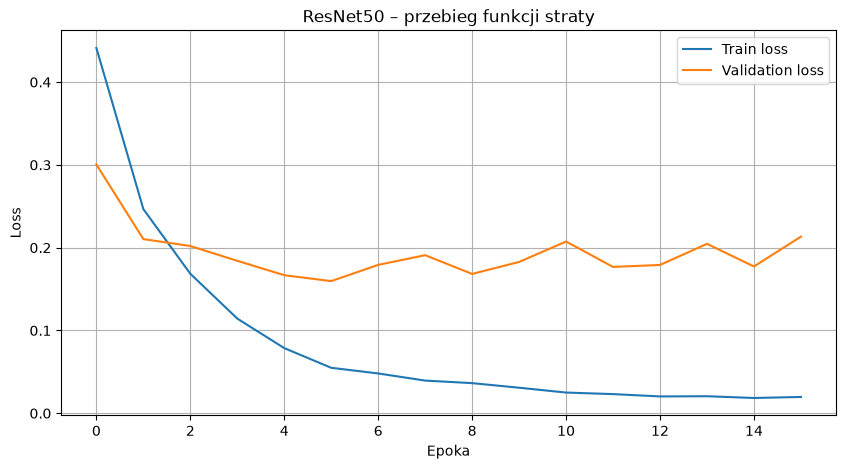

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoka")
plt.ylabel("Loss")
plt.title("ResNet50 - przebieg funkcji straty")

plt.legend()
plt.grid()
plt.show()

In [11]:
f1_per_instrument = f1_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

precision_per_instrument = precision_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

recall_per_instrument = recall_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Instrument": instrument_names,
    "Precision": precision_per_instrument,
    "Recall": recall_per_instrument,
    "F1-score": f1_per_instrument
})

metrics_df

,Instrument,Precision,Recall,F1-score
0,Gitara akustyczna,0.983800,0.824691,0.897246
1,Saksofon altowy,0.961722,0.845722,0.900000
2,Fortepian,0.936937,0.916877,0.926798
3,Perkusja,0.993939,0.982036,0.987952
4,Gitara basowa,0.978589,0.935018,0.956308
5,Flet,0.945774,0.831697,0.885075
6,Sekcja smyczkowa,0.994505,0.886169,0.937217


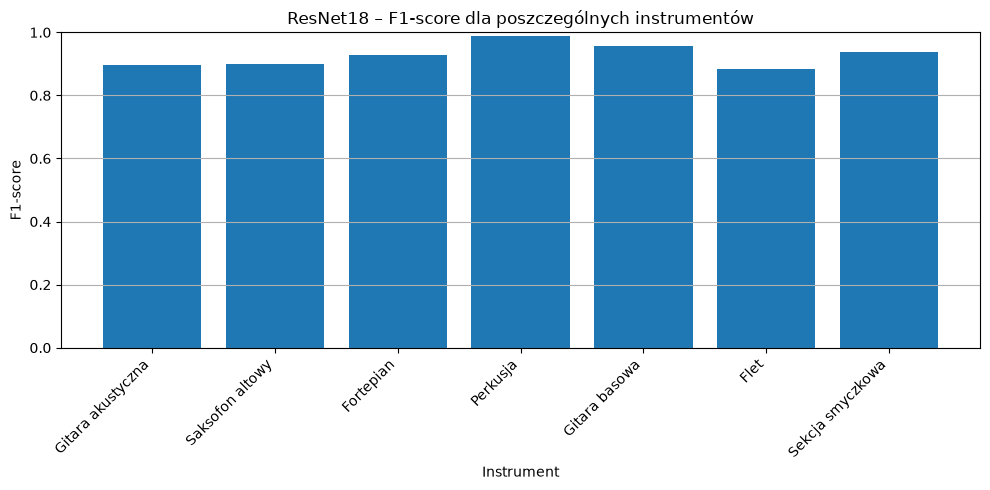

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(instrument_names, f1_per_instrument)

plt.xlabel("Instrument")
plt.ylabel("F1-score")
plt.title("ResNet18 – F1-score dla poszczególnych instrumentów")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.tight_layout()
plt.show()